In [8]:
from pathlib import Path

import kwant
import matplotlib.pyplot as plt

from quantum_billiard import load_parameters, make_system_from_svg

params = load_parameters(Path('parameters.toml'))
system = make_system_from_svg(Path('system.svg'), params.hopping, params.energy)

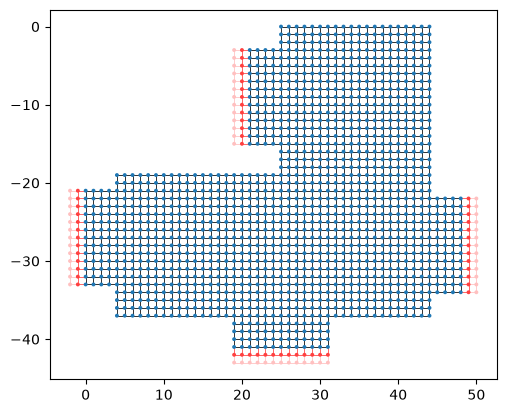

In [9]:
kwant.plot(system);

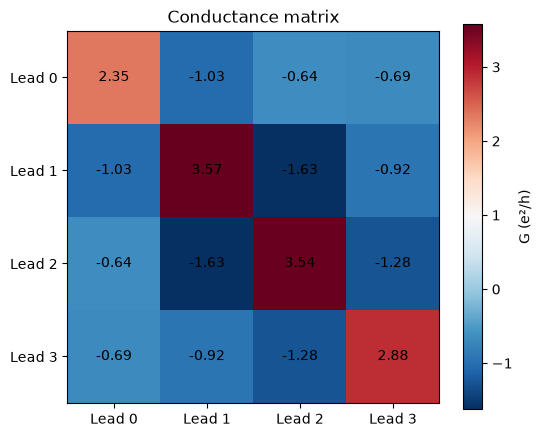

In [10]:
conductance = kwant.smatrix(system, energy=params.energy).conductance_matrix()
n = len(conductance)
labels = [f'Lead {i}' for i in range(n)]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(conductance, cmap='RdBu_r')
ax.set_xticks(range(n), labels)
ax.set_yticks(range(n), labels)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f'{conductance[i, j]:.2f}', ha='center', va='center')
ax.set_title('Conductance matrix')
fig.colorbar(im, label='G (e²/h)')
plt.show()

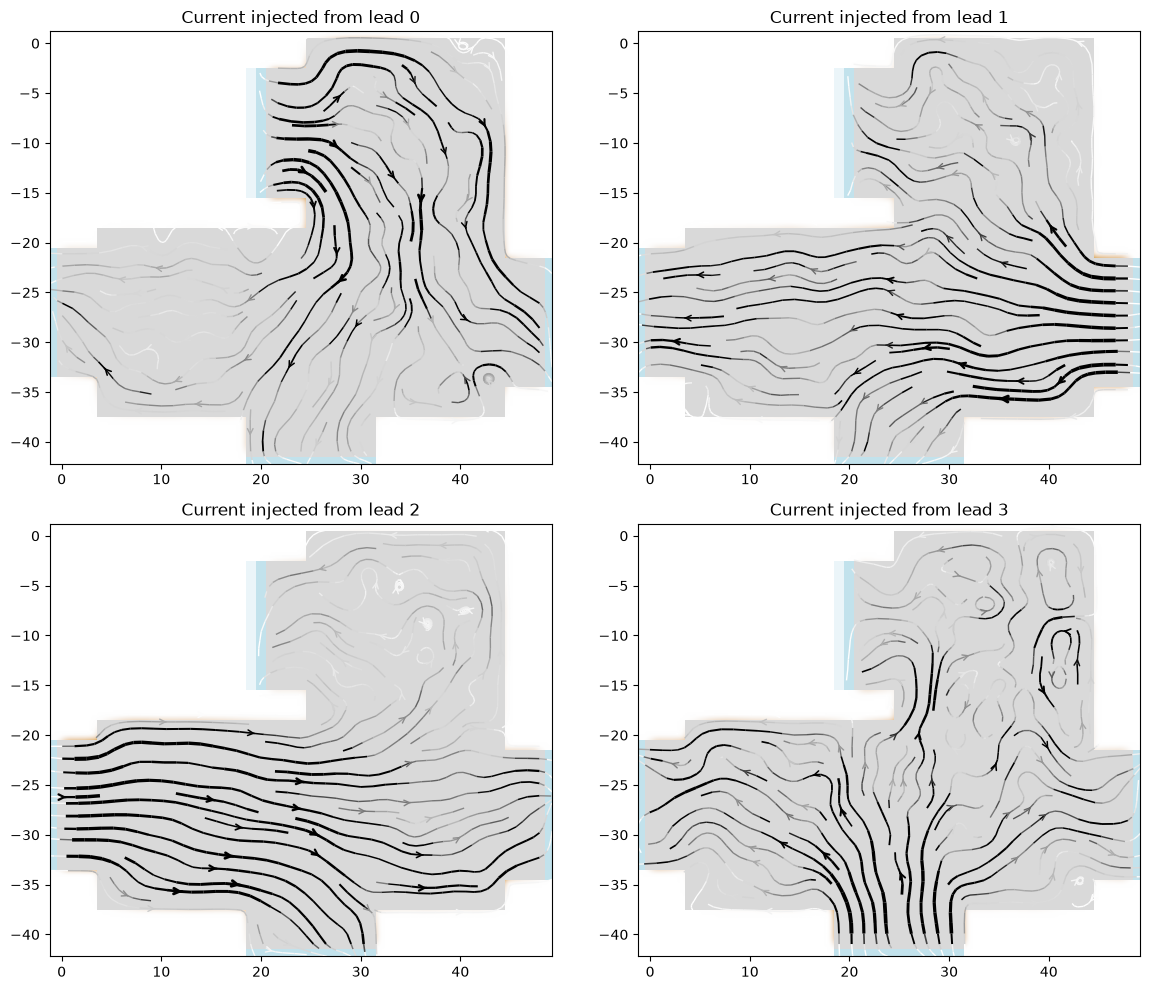

In [11]:
import numpy as np

wave_functions = kwant.wave_function(system, params.energy)
current_operator = kwant.operator.Current(system)

ncols = 2
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)
for lead, ax in zip(range(n), axes.ravel()):
    # Draw the scattering region (gray) and leads (blue) underneath the current
    kwant.plot(system, ax=ax, site_symbol='s', site_size=0.5, site_color='0.85',
               hop_lw=0, lead_site_symbol='s', lead_site_size=0.5,
               lead_color='lightblue', lead_site_lw=0)
    # Sum over all propagating modes injected from this lead
    current = sum(current_operator(psi) for psi in wave_functions(lead))
    kwant.plotter.current(system, current, ax=ax, colorbar=False)
    ax.set_title(f'Current injected from lead {lead}')
for ax in axes.ravel()[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()